# Taller: comparación empírica de 5 algoritmos de ordenamiento

**Materia:** Estructura de Datos · **Programa:** Ingeniería en Ciencia de Datos — UIS

**Objetivo.** Implementar a mano cinco algoritmos de ordenamiento (inserción, burbuja,
selección, *merge sort* y *quicksort*) y compararlos empíricamente sobre muestras de una
misma lista de 200.000 enteros.

**Regla clave.** *Todo* el ordenamiento está escrito en este notebook con bucles,
comparaciones e intercambios. Está prohibido usar funciones o librerías que ordenen:
`sorted()`, `list.sort()`, `heapq`, `bisect`, `numpy.sort`, `pandas.sort_values`,
`sortedcontainers`, etc. La mezcla de *merge sort* también se escribe a mano.

**Plan del notebook**

1. Configuración (parámetros, rutas, semilla).
2. Generación de `data/numeros.txt` (200.000 enteros, reproducible con semilla 42).
3. Los cinco algoritmos, uno por celda.
4. Validación con `assert` (sin `sorted()`): orden correcto y mismos elementos.
5. Estimación previa de tiempos y plan del benchmark.
6. Benchmark: 5 repeticiones por combinación, guardado parcial en `results/tiempos.csv`.
7. Tabla de promedios y desviaciones (`results/promedios.csv`).
8. Gráficas lineal y log-log (PNG en `results/`).
9. Ajuste de curvas con `scipy.optimize.curve_fit` (R², RMSE y pendiente log-log).
10. Conclusiones.

## 1. Configuración

`QUICK_MODE = True` corre pocos tamaños y 2 repeticiones para validar el notebook en
minutos. `QUICK_MODE = False` es el modo completo y final. El resto de parámetros
(semilla, tamaños, repeticiones y límite de tiempo) se usan tal cual en el informe.

In [1]:
# ====================== Configuración ======================
import csv
import math
import time
import random
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from IPython.display import display

# --- Modo de ejecución -------------------------------------------------
# True  -> tamaños hasta 10.000 y 2 repeticiones (validación rápida).
# False -> modo completo y final (7 tamaños y 5 repeticiones).
QUICK_MODE = False

# --- Parámetros del experimento ---------------------------------------
SEMILLA = 42                 # semilla fija para reproducibilidad
N_TOTAL = 200_000            # enteros del archivo data/numeros.txt
TAMANOS = [500, 1_000, 10_000, 30_000, 50_000, 100_000, 200_000]
REPETICIONES = 5             # repeticiones por combinación (modo completo)
MAX_SEGUNDOS_POR_CORRIDA = 300.0   # omitir una corrida si su estimación lo supera

# Tope de n para los O(n²). En la corrida corta de prueba es 30.000;
# en la corrida final se sube a 200.000 (sin tope real, solo manda el límite de tiempo).
N_MAX_CUADRATICOS = 30_000
CUADRATICOS = ("insercion", "burbuja", "seleccion")

# Nombres de cada tamaño tal como los pide el enunciado
NOMBRES_TAMANO = {
    500: "quinientos",
    1_000: "mil",
    10_000: "diez mil",
    30_000: "treinta mil",
    50_000: "cincuenta mil",
    100_000: "cien mil",
    200_000: "doscientos mil",
}

# --- Rutas (funcionan corriendo desde la raíz o desde notebooks/) ------
RAIZ = Path.cwd()
if RAIZ.name == "notebooks":        # en VS Code el cwd es la carpeta del notebook
    RAIZ = RAIZ.parent
DATA_DIR = RAIZ / "data"
RESULTS_DIR = RAIZ / "results"
ARCHIVO_NUMEROS = DATA_DIR / "numeros.txt"

DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# --- Ajuste del modo ---------------------------------------------------
if QUICK_MODE:
    TAMANOS_RUN = [500, 1_000, 10_000]
    REPETICIONES_RUN = 2
else:
    TAMANOS_RUN = TAMANOS
    REPETICIONES_RUN = REPETICIONES

random.seed(SEMILLA)          # fija la semilla para quicksort (pivote aleatorio)

print(f"QUICK_MODE           = {QUICK_MODE}")
print(f"Semilla              = {SEMILLA}")
print(f"Tamaños en esta run  = {TAMANOS_RUN}")
print(f"Repeticiones         = {REPETICIONES_RUN}")
print(f"Raíz del proyecto    = {RAIZ}")

QUICK_MODE           = False
Semilla              = 42
Tamaños en esta run  = [500, 1000, 10000, 30000, 50000, 100000, 200000]
Repeticiones         = 5
Raíz del proyecto    = /home/ilohu/Python/Estructura_de_datos/talleralgortimos


## 2. Generación de datos

Se escriben 200.000 enteros (uno por línea) con `random.randint` y la semilla fija.
Todas las muestras del benchmark son **prefijos** de la misma lista, así que un tamaño
mayor contiene exactamente los mismos valores que uno menor. Si el archivo ya existe
solo se lee, para no perder tiempo regenerando.

In [2]:
# ---------------------- Generar / leer data/numeros.txt ----------------------
if ARCHIVO_NUMEROS.exists():
    print(f"Ya existe {ARCHIVO_NUMEROS} (no se regenera).")
else:
    random.seed(SEMILLA)
    with open(ARCHIVO_NUMEROS, "w", encoding="utf-8") as f:
        for _ in range(N_TOTAL):
            f.write(f"{random.randint(0, 1_000_000)}\n")
    print(f"Generados {N_TOTAL} enteros en {ARCHIVO_NUMEROS}.")

# Leer el archivo a una lista de Python (sin ordenar nada aquí)
with open(ARCHIVO_NUMEROS, encoding="utf-8") as f:
    DATOS = [int(linea) for linea in f]

print(f"Leídos {len(DATOS)} enteros | mínimo = {min(DATOS)} | máximo = {max(DATOS)}")
print("Primeros 5 valores:", DATOS[:5])

Ya existe /home/ilohu/Python/Estructura_de_datos/talleralgortimos/data/numeros.txt (no se regenera).
Leídos 200000 enteros | mínimo = 6 | máximo = 999994
Primeros 5 valores: [670487, 116739, 26225, 777572, 288389]


## 3. Los cinco algoritmos, escritos a mano

Cada celda define una función y anota su complejidad teórica. Ninguna usa funciones de
ordenamiento de librerías.

### 3.1 Inserción — *Insertion sort*

Complejidad: **O(n²)** en el peor caso y en promedio; **O(n)** en el mejor caso
(lista ya ordenada). Es estable y en la práctica el más rápido de los cuadráticos
porque el bucle interno suele tocar pocos elementos.

In [3]:
def ordenamiento_insercion(lista):
    '''Ordena 'lista' in-place por inserción. Complejidad O(n^2).'''
    for i in range(1, len(lista)):
        clave = lista[i]
        j = i - 1
        # Mover a la derecha los elementos mayores que la clave
        while j >= 0 and lista[j] > clave:
            lista[j + 1] = lista[j]
            j -= 1
        lista[j + 1] = clave
    return lista

### 3.2 Burbuja — *Bubble sort*

Complejidad: **O(n²)** siempre (peor y promedio). Con la bandera `hubo_cambio` corta
temprano si la lista ya está ordenada (mejor caso O(n)). Es estable pero hace muchos
intercambios, por eso suele ser el más lento de los tres.

In [4]:
def ordenamiento_burbuja(lista):
    '''Ordena 'lista' in-place por burbuja. Complejidad O(n^2).'''
    n = len(lista)
    for i in range(n - 1):
        hubo_cambio = False
        # Tras la pasada i, los i últimos ya están en su lugar
        for j in range(n - 1 - i):
            if lista[j] > lista[j + 1]:
                lista[j], lista[j + 1] = lista[j + 1], lista[j]
                hubo_cambio = True
        if not hubo_cambio:
            break   # ya está ordenada
    return lista

### 3.3 Selección — *Selection sort*

Complejidad: **O(n²)** en todos los casos, porque siempre recorre el resto para buscar
el mínimo. Hace pocos intercambios (a lo sumo n−1) pero muchas comparaciones. No es
estable.

In [5]:
def ordenamiento_seleccion(lista):
    '''Ordena 'lista' in-place por selección. Complejidad O(n^2).'''
    n = len(lista)
    for i in range(n - 1):
        idx_min = i
        for j in range(i + 1, n):
            if lista[j] < lista[idx_min]:
                idx_min = j
        if idx_min != i:
            lista[i], lista[idx_min] = lista[idx_min], lista[i]
    return lista

### 3.4 Merge sort — *Ordenamiento por mezcla*

Complejidad: **O(n log n)** siempre. Divide la lista a la mitad, ordena cada mitad
recursivamente y las mezcla. La mezcla está escrita a mano (sin `heapq.merge`). Es
estable, pero crea listas auxiliares (no ordena in-place).

In [6]:
def _mezclar(izquierda, derecha):
    '''Mezcla dos listas ya ordenadas en una nueva (escrita a mano).'''
    resultado = []
    i = j = 0
    while i < len(izquierda) and j < len(derecha):
        if izquierda[i] <= derecha[j]:
            resultado.append(izquierda[i])
            i += 1
        else:
            resultado.append(derecha[j])
            j += 1
    # Sobrantes de cualquiera de las dos listas
    resultado.extend(izquierda[i:])
    resultado.extend(derecha[j:])
    return resultado


def ordenamiento_mezcla(lista):
    '''Devuelve una lista nueva ordenada por mezcla. Complejidad O(n log n).'''
    if len(lista) <= 1:
        return list(lista)
    medio = len(lista) // 2
    izquierda = ordenamiento_mezcla(lista[:medio])
    derecha = ordenamiento_mezcla(lista[medio:])
    return _mezclar(izquierda, derecha)

### 3.5 Quicksort — *Ordenamiento rápido*

Complejidad: **O(n log n)** en promedio y **O(n²)** en el peor caso. Usa un **pivote
aleatorio** (con la semilla fija) para evitar el peor caso con datos ya ordenados.

La recursión se reemplaza por una **pila explícita** y siempre se apila primero la
partición *pequeña*: así el número máximo de particiones pendientes es O(log n) y no se
supera el límite de recursión de Python (~1000), que se rompería al ordenar 200.000
elementos con recursión sobre la partición grande.

In [7]:
def _particion(lista, inicio, fin):
    '''Particiona lista[inicio..fin] con pivote aleatorio y devuelve su índice final.'''
    idx_pivote = random.randint(inicio, fin)
    lista[idx_pivote], lista[fin] = lista[fin], lista[idx_pivote]   # pivote al final
    pivote = lista[fin]
    i = inicio - 1
    for j in range(inicio, fin):
        if lista[j] <= pivote:
            i += 1
            lista[i], lista[j] = lista[j], lista[i]
    lista[i + 1], lista[fin] = lista[fin], lista[i + 1]
    return i + 1


def ordenamiento_rapido(lista):
    '''Ordena 'lista' in-place con quicksort iterativo (pila explícita, pivote aleatorio).'''
    pila = [(0, len(lista) - 1)]
    while pila:
        inicio, fin = pila.pop()
        if inicio >= fin:
            continue
        p = _particion(lista, inicio, fin)
        # Apilamos primero el lado MAYOR y dejamos el menor en el tope:
        # así el tamaño de la pila se mantiene O(log n).
        izq = (inicio, p - 1)
        der = (p + 1, fin)
        mayor, menor = (izq, der) if (izq[1] - izq[0]) >= (der[1] - der[0]) else (der, izq)
        pila.append(mayor)
        pila.append(menor)
    return lista

## 4. Validación con `assert` (sin usar `sorted()`)

Antes del benchmark comprobamos que los cinco algoritmos:

- dejan la lista **ordenada**, con `es_ordenada()`, que verifica `lista[i] <= lista[i+1]`;
- conservan **exactamente los mismos elementos**, comparando con `collections.Counter`.

Se prueban listas pequeñas aleatorias y casos borde: vacía, un elemento, duplicados, ya
ordenada e inversa.

In [8]:
ALGORITMOS = {
    "insercion": ordenamiento_insercion,
    "burbuja": ordenamiento_burbuja,
    "seleccion": ordenamiento_seleccion,
    "mezcla": ordenamiento_mezcla,
    "rapido": ordenamiento_rapido,
}

# Nombres para mostrar en tablas y gráficas
NOMBRES = {
    "insercion": "Inserción",
    "burbuja": "Burbuja",
    "seleccion": "Selección",
    "mezcla": "Merge sort",
    "rapido": "Quicksort",
}


def es_ordenada(lista):
    '''True si lista[i] <= lista[i+1] para todo i. NO usa sorted().'''
    for i in range(len(lista) - 1):
        if lista[i] > lista[i + 1]:
            return False
    return True


random.seed(SEMILLA)   # casos de prueba reproducibles

casos = {
    "vacia": [],
    "un_elemento": [42],
    "ya_ordenada": list(range(30)),
    "inversa": list(range(30, 0, -1)),
    "duplicados": [7] * 12 + [3] * 8 + [5] * 4,
    "aleatoria_pequena": [random.randint(0, 100) for _ in range(60)],
    "aleatoria_200": [random.randint(0, 10_000) for _ in range(200)],
}

pruebas_ok = 0
for nombre, funcion in ALGORITMOS.items():
    for caso, original in casos.items():
        resultado = funcion(list(original))
        assert es_ordenada(resultado), f"{nombre} no ordenó el caso '{caso}'"
        assert Counter(resultado) == Counter(original), \
            f"{nombre} alteró los elementos en el caso '{caso}'"
        pruebas_ok += 1

print(f"Validación superada: {pruebas_ok} combinaciones (algoritmo, caso) sin errores.")
print("Los 5 algoritmos ordenan y conservan los elementos en todos los casos borde.")

Validación superada: 35 combinaciones (algoritmo, caso) sin errores.
Los 5 algoritmos ordenan y conservan los elementos en todos los casos borde.


## 5. Estimación previa y plan del benchmark

En Python puro los O(n²) tardarían **decenas de minutos** con 200.000 elementos por
corrida. Para no bloquear el notebook, antes del benchmark medimos cada algoritmo con
n = 2.000 y extrapolamos:

- O(n²): `t(n) ≈ t(2000) · (n/2000)²`
- O(n log n): `t(n) ≈ t(2000) · (n·log n) / (2000·log 2000)`

Si la estimación de una corrida de un O(n²) supera `MAX_SEGUNDOS_POR_CORRIDA`, ese
tamaño se omite para ese algoritmo (queda `NaN` en la tabla) y se avisa por pantalla.
Merge y quicksort corren todos los tamaños.

In [9]:
# ---------------------- Estimación de tiempos ----------------------
N_ESTIMACION = 2000
muestra_estimacion = DATOS[:N_ESTIMACION]

def _factor(nombre, n):
    if nombre in CUADRATICOS:
        return (n / N_ESTIMACION) ** 2
    return (n * math.log(n)) / (N_ESTIMACION * math.log(N_ESTIMACION))

tiempos_base = {}
print(f"Midiendo cada algoritmo con n = {N_ESTIMACION} (una corrida)...")
for nombre in ALGORITMOS:
    copia = list(muestra_estimacion)
    t0 = time.perf_counter()
    resultado = ALGORITMOS[nombre](copia)   # merge devuelve lista nueva; los demás, la misma
    t1 = time.perf_counter()
    assert es_ordenada(resultado)
    tiempos_base[nombre] = t1 - t0
    print(f"  {NOMBRES[nombre]:11s}: {t1 - t0:.4f} s")

def estimar(tamanos):
    return {(nombre, n): tiempos_base[nombre] * _factor(nombre, n)
            for nombre in ALGORITMOS for n in tamanos}

def decidir_plan(tamanos, estimaciones):
    plan, omitidos = [], []
    for n in tamanos:                       # primero el tamaño, luego el algoritmo
        for nombre in ALGORITMOS:
            est = estimaciones[(nombre, n)]
            if nombre in CUADRATICOS and (n > N_MAX_CUADRATICOS or est > MAX_SEGUNDOS_POR_CORRIDA):
                omitidos.append((nombre, n, est))
            else:
                plan.append((nombre, n))
    return plan, omitidos

estimaciones_full = estimar(TAMANOS)
estimaciones_run = estimar(TAMANOS_RUN)

# Tabla de estimaciones del modo COMPLETO (para decidir)
tabla_estimaciones = pd.DataFrame(
    [[NOMBRES[a]] + [round(estimaciones_full[(a, n)], 2) for n in TAMANOS] for a in ALGORITMOS],
    columns=["algoritmo"] + [str(n) for n in TAMANOS],
).set_index("algoritmo")

print(f"\nEstimación de tiempo por corrida (segundos) para el MODO COMPLETO,")
print(f"límite MAX_SEGUNDOS_POR_CORRIDA = {MAX_SEGUNDOS_POR_CORRIDA:.0f} s:")
display(tabla_estimaciones)

PLAN_FULL, OMITIDOS_FULL = decidir_plan(TAMANOS, estimaciones_full)
print(f"Modo completo: {len(PLAN_FULL)} combinaciones a ejecutar, {len(OMITIDOS_FULL)} omitidas.")
for nombre, n, est in OMITIDOS_FULL:
    print(f"  OMITIDO: {NOMBRES[nombre]:11s} n={n:>7d}  (O(n²), estimado {est:8.1f} s)")

# Plan efectivo de ESTA ejecución
PLAN, OMITIDOS = decidir_plan(TAMANOS_RUN, estimaciones_run)
print(f"\nEsta ejecución (QUICK_MODE={QUICK_MODE}): {len(PLAN)} combinaciones, {len(OMITIDOS)} omitidas.")
for nombre, n, est in OMITIDOS:
    print(f"  OMITIDO: {NOMBRES[nombre]:11s} n={n:>7d}  (estimado {est:8.1f} s)")

Midiendo cada algoritmo con n = 2000 (una corrida)...
  Inserción  : 0.0821 s


  Burbuja    : 0.1888 s
  Selección  : 0.0796 s
  Merge sort : 0.0037 s
  Quicksort  : 0.0027 s

Estimación de tiempo por corrida (segundos) para el MODO COMPLETO,
límite MAX_SEGUNDOS_POR_CORRIDA = 300 s:


,500,1000,10000,30000,50000,100000,200000
algoritmo,,,,,,,
Inserción,0.01,0.02,2.05,18.48,51.33,205.31,821.25
Burbuja,0.01,0.05,4.72,42.47,117.98,471.91,1887.62
Selección,0.00,0.02,1.99,17.92,49.77,199.09,796.37
Merge sort,0.00,0.00,0.02,0.07,0.13,0.28,0.59
Quicksort,0.00,0.00,0.02,0.06,0.10,0.21,0.44


Modo completo: 26 combinaciones a ejecutar, 9 omitidas.
  OMITIDO: Inserción   n=  50000  (O(n²), estimado     51.3 s)
  OMITIDO: Burbuja     n=  50000  (O(n²), estimado    118.0 s)
  OMITIDO: Selección   n=  50000  (O(n²), estimado     49.8 s)
  OMITIDO: Inserción   n= 100000  (O(n²), estimado    205.3 s)
  OMITIDO: Burbuja     n= 100000  (O(n²), estimado    471.9 s)
  OMITIDO: Selección   n= 100000  (O(n²), estimado    199.1 s)
  OMITIDO: Inserción   n= 200000  (O(n²), estimado    821.3 s)
  OMITIDO: Burbuja     n= 200000  (O(n²), estimado   1887.6 s)
  OMITIDO: Selección   n= 200000  (O(n²), estimado    796.4 s)

Esta ejecución (QUICK_MODE=False): 26 combinaciones, 9 omitidas.
  OMITIDO: Inserción   n=  50000  (estimado     51.3 s)
  OMITIDO: Burbuja     n=  50000  (estimado    118.0 s)
  OMITIDO: Selección   n=  50000  (estimado     49.8 s)
  OMITIDO: Inserción   n= 100000  (estimado    205.3 s)
  OMITIDO: Burbuja     n= 100000  (estimado    471.9 s)
  OMITIDO: Selección   n= 10000

## 6. Benchmark, dividido por tamaño de prueba

El enunciado pide probar, **en este orden**: quinientos, mil, diez mil, treinta mil,
cincuenta mil, cien mil y doscientos mil números. Por eso el benchmark está dividido en
una celda por cada tamaño; cada celda llama a `ejecutar_prueba(n)`, que:

- ordena una **copia** de la muestra (`list(muestra)`) y mide con `time.perf_counter()`;
- repite `REPETICIONES_RUN` veces y promedia después;
- omite los O(n²) cuando su estimación supera el límite (o cuando `n` pasa el tope
  `N_MAX_CUADRATICOS`);
- **guarda el avance** en `results/tiempos.csv` apenas termina cada combinación.

Se pueden ejecutar todas las celdas seguidas (con *Run All*) o una por una en VS Code.

In [10]:
# ---------------------- Preparación del benchmark ----------------------
RUTA_TIEMPOS = RESULTS_DIR / "tiempos.csv"
RUTA_PROMEDIOS = RESULTS_DIR / "promedios.csv"
RUTA_PROGRESO = RESULTS_DIR / "progreso.log"
ENCABEZADO = ["algoritmo", "n", "repeticion", "tiempo_s"]


def _log(mensaje):
    '''Imprime en el notebook y además escribe en results/progreso.log (para tail -f).'''
    print(mensaje, flush=True)
    with open(RUTA_PROGRESO, "a", encoding="utf-8") as f:
        f.write(mensaje + "\n")


# Se empieza de cero: tiempos.csv con encabezado y progreso.log vacío.
with open(RUTA_TIEMPOS, "w", newline="", encoding="utf-8") as archivo:
    csv.DictWriter(archivo, fieldnames=ENCABEZADO).writeheader()
with open(RUTA_PROGRESO, "w", encoding="utf-8") as f:
    f.write(f"Inicio: QUICK_MODE={QUICK_MODE}, repeticiones={REPETICIONES_RUN}, "
            f"tope O(n²)={N_MAX_CUADRATICOS}\n")

filas = []   # todas las mediciones de la corrida


def ejecutar_prueba(n):
    '''Corre los algoritmos viables para el tamaño n y guarda el avance en el CSV.'''
    if n not in TAMANOS_RUN:
        _log(f"  (n={n} no se prueba en esta ejecución: QUICK_MODE={QUICK_MODE})")
        return
    _log(f"PRUEBA n={n:,} ({NOMBRES_TAMANO[n]})".replace(",", "."))
    for nombre in ALGORITMOS:
        if nombre in CUADRATICOS and n > N_MAX_CUADRATICOS:
            _log(f"  {NOMBRES[nombre]:11s}: omitido (O(n²) con n > {N_MAX_CUADRATICOS:,})".replace(",", "."))
            continue
        if nombre in CUADRATICOS and estimaciones_run[(nombre, n)] > MAX_SEGUNDOS_POR_CORRIDA:
            _log(f"  {NOMBRES[nombre]:11s}: omitido (estimado > {MAX_SEGUNDOS_POR_CORRIDA:.0f} s)")
            continue

        muestra = DATOS[:n]
        nuevas = []
        for rep in range(1, REPETICIONES_RUN + 1):
            copia = list(muestra)              # copia: la muestra original no se toca
            t0 = time.perf_counter()
            resultado = ALGORITMOS[nombre](copia)   # merge devuelve lista nueva
            t1 = time.perf_counter()
            dt = t1 - t0
            assert es_ordenada(resultado), f"{nombre} con n={n} no quedó ordenado"
            fila = {"algoritmo": nombre, "n": n, "repeticion": rep, "tiempo_s": dt}
            filas.append(fila)
            nuevas.append(fila)
            _log(f"  {NOMBRES[nombre]:11s} rep {rep}/{REPETICIONES_RUN}: {dt:.4f} s")

        with open(RUTA_TIEMPOS, "a", newline="", encoding="utf-8") as archivo:   # guardado parcial
            csv.DictWriter(archivo, fieldnames=ENCABEZADO).writerows(nuevas)


_log("Benchmark preparado: una prueba por tamaño, en el orden del enunciado.")

Benchmark preparado: una prueba por tamaño, en el orden del enunciado.


In [11]:
ejecutar_prueba(500)      # quinientos números

PRUEBA n=500 (quinientos)


  Inserción   rep 1/5: 0.0047 s


  Inserción   rep 2/5: 0.0040 s


  Inserción   rep 3/5: 0.0035 s


  Inserción   rep 4/5: 0.0038 s


...

  Quicksort   rep 1/5: 0.0005 s


  Quicksort   rep 2/5: 0.0023 s


  Quicksort   rep 3/5: 0.0011 s


  Quicksort   rep 4/5: 0.0006 s


  Quicksort   rep 5/5: 0.0006 s


In [12]:
ejecutar_prueba(1_000)    # mil números

PRUEBA n=1.000 (mil)


  Inserción   rep 1/5: 0.0198 s


  Inserción   rep 2/5: 0.0166 s


  Inserción   rep 3/5: 0.0175 s


  Inserción   rep 4/5: 0.0177 s


...

  Quicksort   rep 1/5: 0.0013 s


  Quicksort   rep 2/5: 0.0011 s


  Quicksort   rep 3/5: 0.0017 s


  Quicksort   rep 4/5: 0.0014 s


  Quicksort   rep 5/5: 0.0034 s


In [13]:
ejecutar_prueba(10_000)   # diez mil números

PRUEBA n=10.000 (diez mil)


  Inserción   rep 1/5: 2.3448 s


  Inserción   rep 2/5: 2.6644 s


  Inserción   rep 3/5: 2.3714 s


  Inserción   rep 4/5: 1.9714 s


...

  Quicksort   rep 1/5: 0.0570 s


  Quicksort   rep 2/5: 0.0518 s


  Quicksort   rep 3/5: 0.0351 s


  Quicksort   rep 4/5: 0.0202 s


  Quicksort   rep 5/5: 0.0210 s


In [14]:
ejecutar_prueba(30_000)   # treinta mil números

PRUEBA n=30.000 (treinta mil)


  Inserción   rep 1/5: 20.0111 s


  Inserción   rep 2/5: 19.7737 s


  Inserción   rep 3/5: 20.9453 s


  Inserción   rep 4/5: 20.7621 s


...

  Quicksort   rep 1/5: 0.0600 s


  Quicksort   rep 2/5: 0.0568 s


  Quicksort   rep 3/5: 0.0448 s


  Quicksort   rep 4/5: 0.0491 s


  Quicksort   rep 5/5: 0.0484 s


In [15]:
ejecutar_prueba(50_000)   # cincuenta mil números

PRUEBA n=50.000 (cincuenta mil)


  Inserción  : omitido (O(n²) con n > 30.000)


  Burbuja    : omitido (O(n²) con n > 30.000)


  Selección  : omitido (O(n²) con n > 30.000)


  Merge sort  rep 1/5: 0.1134 s


...

  Quicksort   rep 1/5: 0.0914 s


  Quicksort   rep 2/5: 0.0907 s


  Quicksort   rep 3/5: 0.0935 s


  Quicksort   rep 4/5: 0.1036 s


  Quicksort   rep 5/5: 0.1030 s


In [16]:
ejecutar_prueba(100_000)  # cien mil números

PRUEBA n=100.000 (cien mil)


  Inserción  : omitido (O(n²) con n > 30.000)


  Burbuja    : omitido (O(n²) con n > 30.000)


  Selección  : omitido (O(n²) con n > 30.000)


  Merge sort  rep 1/5: 0.2598 s


...

  Quicksort   rep 1/5: 0.2159 s


  Quicksort   rep 2/5: 0.2070 s


  Quicksort   rep 3/5: 0.1929 s


  Quicksort   rep 4/5: 0.1926 s


  Quicksort   rep 5/5: 0.1991 s


In [17]:
ejecutar_prueba(200_000)  # doscientos mil números

PRUEBA n=200.000 (doscientos mil)


  Inserción  : omitido (O(n²) con n > 30.000)


  Burbuja    : omitido (O(n²) con n > 30.000)


  Selección  : omitido (O(n²) con n > 30.000)


  Merge sort  rep 1/5: 0.5600 s


...

  Quicksort   rep 1/5: 0.4072 s


  Quicksort   rep 2/5: 0.4187 s


  Quicksort   rep 3/5: 0.4408 s


  Quicksort   rep 4/5: 0.4297 s


  Quicksort   rep 5/5: 0.3782 s


In [18]:
df_tiempos = pd.DataFrame(filas)
print(f"Terminado. {len(df_tiempos)} mediciones guardadas en {RUTA_TIEMPOS}")

Terminado. 130 mediciones guardadas en /home/ilohu/Python/Estructura_de_datos/talleralgortimos/results/tiempos.csv


## 7. Tabla de promedios y desviaciones

Promedio y desviación estándar por algoritmo y tamaño. Las combinaciones omitidas
quedan como `NaN`. Se guarda también `results/promedios.csv`. No se usa `sort_values()`.

In [19]:
# ---------------------- Promedios y desviaciones ----------------------
resumen = (df_tiempos
           .groupby(["algoritmo", "n"], as_index=False)["tiempo_s"]
           .agg(promedio_s="mean", desv_s="std"))

# Completar las combinaciones omitidas con NaN
todas = pd.MultiIndex.from_product([list(ALGORITMOS.keys()), TAMANOS_RUN],
                                   names=["algoritmo", "n"])
resumen = resumen.set_index(["algoritmo", "n"]).reindex(todas).reset_index()
resumen["algoritmo_es"] = resumen["algoritmo"].map(NOMBRES)
resumen = resumen[["algoritmo", "algoritmo_es", "n", "promedio_s", "desv_s"]]
resumen.to_csv(RUTA_PROMEDIOS, index=False)

orden_algoritmos = [NOMBRES[a] for a in ALGORITMOS]
tabla_promedio = (resumen.pivot(index="algoritmo_es", columns="n", values="promedio_s")
                  .reindex(orden_algoritmos))
tabla_desv = (resumen.pivot(index="algoritmo_es", columns="n", values="desv_s")
              .reindex(orden_algoritmos))

print("Tiempo promedio (segundos) por algoritmo y tamaño:")
display(tabla_promedio.round(4))
print("Desviación estándar (segundos):")
display(tabla_desv.round(4))
print(f"Guardado en {RUTA_PROMEDIOS}")

Tiempo promedio (segundos) por algoritmo y tamaño:


n,500,1000,10000,30000,50000,100000,200000
algoritmo_es,,,,,,,
Inserción,0.0039,0.0176,2.3203,20.4506,NaN,NaN,NaN
Burbuja,0.0099,0.0409,4.5645,47.8461,NaN,NaN,NaN
Selección,0.0047,0.0191,1.8242,18.6374,NaN,NaN,NaN
Merge sort,0.0007,0.0015,0.0276,0.0745,0.1162,0.2690,0.5404
Quicksort,0.0010,0.0018,0.0370,0.0519,0.0964,0.2015,0.4149


Desviación estándar (segundos):


n,500,1000,10000,30000,50000,100000,200000
algoritmo_es,,,,,,,
Inserción,0.0005,0.0014,0.2492,0.5218,NaN,NaN,NaN
Burbuja,0.0016,0.0019,0.0466,4.8580,NaN,NaN,NaN
Selección,0.0011,0.0023,0.0045,1.5538,NaN,NaN,NaN
Merge sort,0.0001,0.0001,0.0073,0.0201,0.0050,0.0237,0.0113
Quicksort,0.0008,0.0009,0.0170,0.0063,0.0063,0.0100,0.0240


Guardado en /home/ilohu/Python/Estructura_de_datos/talleralgortimos/results/promedios.csv


## 8. Gráficas

Se dibuja el tiempo promedio contra n en escala lineal y en escala log-log, y una
gráfica aparte solo con merge sort y quicksort (los dos O(n log n)).

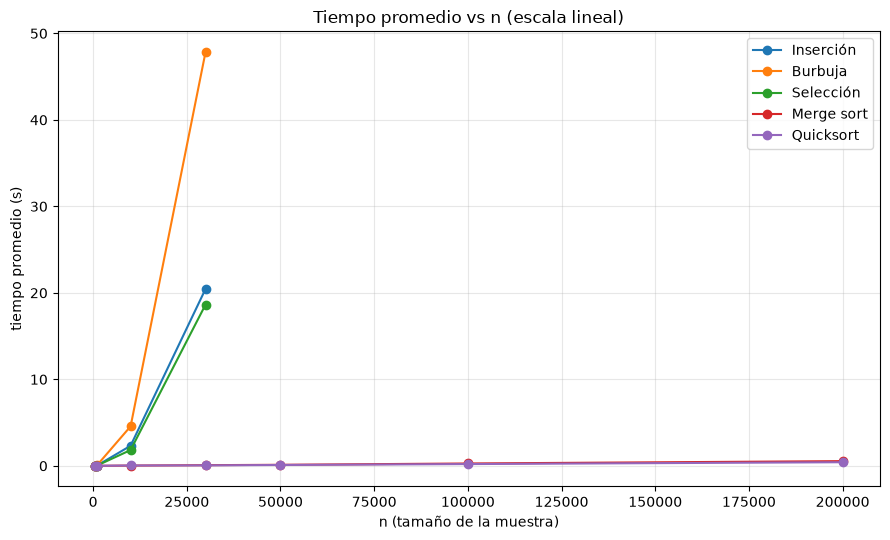

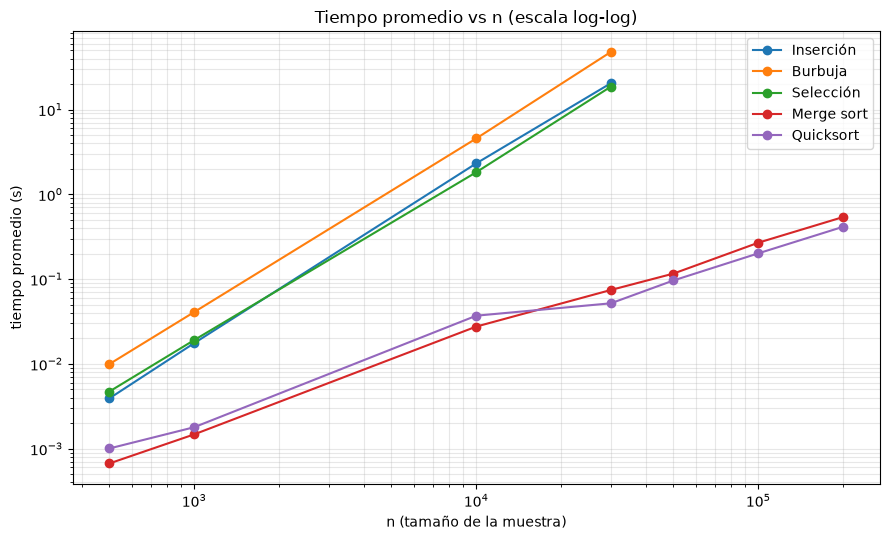

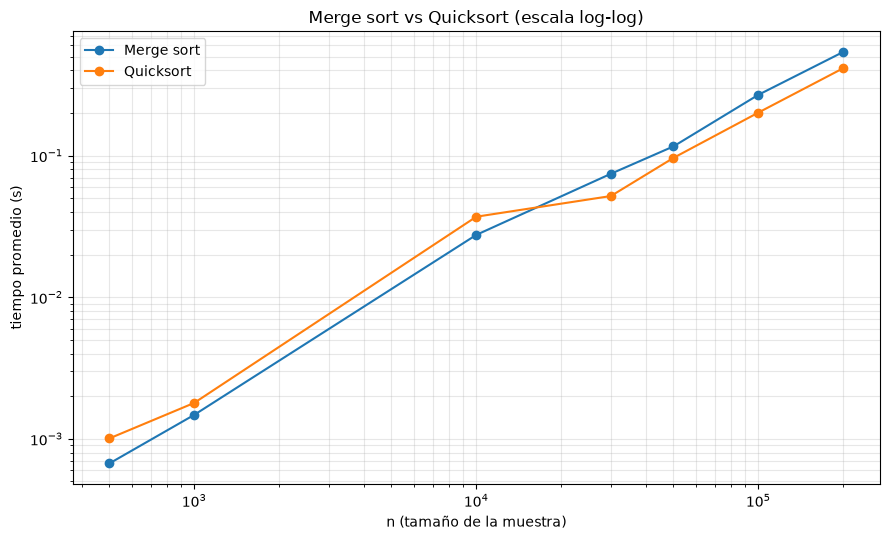

In [20]:
# ---------------------- Gráficas ----------------------
def serie_xy(algoritmo):
    '''Devuelve (n, tiempo) con los puntos disponibles (sin NaN) de un algoritmo.'''
    fila = tabla_promedio.loc[NOMBRES[algoritmo]]
    xs = [n for n in TAMANOS_RUN if pd.notna(fila[n])]
    ys = [fila[n] for n in xs]
    return xs, ys

def graficar(escala_log, algoritmos, titulo, archivo):
    fig, ax = plt.subplots(figsize=(9, 5.5))
    for a in algoritmos:
        xs, ys = serie_xy(a)
        ax.plot(xs, ys, marker="o", label=NOMBRES[a])
    if escala_log:
        ax.set_xscale("log")
        ax.set_yscale("log")
    ax.set_title(titulo)
    ax.set_xlabel("n (tamaño de la muestra)")
    ax.set_ylabel("tiempo promedio (s)")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / archivo, dpi=150)
    return fig

fig_lineal = graficar(False, list(ALGORITMOS.keys()),
                      "Tiempo promedio vs n (escala lineal)", "tiempos_lineal.png")
plt.show()

fig_loglog = graficar(True, list(ALGORITMOS.keys()),
                      "Tiempo promedio vs n (escala log-log)", "tiempos_loglog.png")
plt.show()

fig_nlogn = graficar(True, ["mezcla", "rapido"],
                     "Merge sort vs Quicksort (escala log-log)", "tiempos_merge_quick.png")
plt.show()

## 9. Ajuste de funciones

Para cada algoritmo se ajustan tres modelos con `curve_fit` y se comparan por R² y RMSE:

| modelo | forma | esperado en |
|---|---|---|
| lineal | `a·n + b` | referencia |
| n·log(n) | `a·n·log(n) + b` | merge sort, quicksort |
| cuadrático | `a·n² + b` | inserción, burbuja, selección |

Como en los O(n²) puede haber pocos puntos (los tamaños grandes se omiten), se calcula
también la **pendiente en escala log-log**: ≈1–1,2 para n·log(n) y ≈2 para n².

In [21]:
# ---------------------- Ajuste de curvas ----------------------
def modelo_n(n, a, b):
    return a * n + b

def modelo_nlogn(n, a, b):
    return a * n * np.log(n) + b

def modelo_n2(n, a, b):
    return a * n ** 2 + b

MODELOS = {
    "a·n + b": modelo_n,
    "a·n·log(n) + b": modelo_nlogn,
    "a·n² + b": modelo_n2,
}

def r2(y, yhat):
    ss_res = float(np.sum((y - yhat) ** 2))
    ss_tot = float(np.sum((y - np.mean(y)) ** 2))
    return 1.0 - ss_res / ss_tot if ss_tot > 0 else float("nan")

def rmse(y, yhat):
    return float(np.sqrt(np.mean((y - yhat) ** 2)))

datos_ajuste = {}
filas_ajuste = []
for nombre in ALGORITMOS:
    xs, ys = serie_xy(nombre)
    n_vals = np.array(xs, dtype=float)
    t_vals = np.array(ys, dtype=float)
    datos_ajuste[nombre] = (n_vals, t_vals)

    pendiente = float(np.polyfit(np.log(n_vals), np.log(t_vals), 1)[0]) if len(n_vals) >= 2 else float("nan")

    for etiqueta, fn in MODELOS.items():
        if len(n_vals) < 2:
            filas_ajuste.append({"algoritmo": NOMBRES[nombre], "modelo": etiqueta,
                                 "R2": float("nan"), "RMSE": float("nan"),
                                 "a": float("nan"), "b": float("nan"),
                                 "pendiente_loglog": pendiente, "n_puntos": len(n_vals)})
            continue
        try:
            popt, _ = curve_fit(fn, n_vals, t_vals, p0=[1e-6, 0.0], maxfev=20_000)
            yhat = fn(n_vals, *popt)
            filas_ajuste.append({"algoritmo": NOMBRES[nombre], "modelo": etiqueta,
                                 "R2": r2(t_vals, yhat), "RMSE": rmse(t_vals, yhat),
                                 "a": float(popt[0]), "b": float(popt[1]),
                                 "pendiente_loglog": pendiente, "n_puntos": len(n_vals)})
        except Exception as exc:
            filas_ajuste.append({"algoritmo": NOMBRES[nombre], "modelo": etiqueta,
                                 "R2": float("nan"), "RMSE": float("nan"),
                                 "a": float("nan"), "b": float("nan"),
                                 "pendiente_loglog": pendiente, "n_puntos": len(n_vals)})

df_ajustes = pd.DataFrame(filas_ajuste)

# Mejor modelo por algoritmo = menor RMSE (sin usar sort_values)
mejores = {}
for nombre in ALGORITMOS:
    sub = df_ajustes[df_ajustes["algoritmo"] == NOMBRES[nombre]].dropna(subset=["RMSE"])
    if len(sub):
        mejores[nombre] = sub.loc[sub["RMSE"].idxmin()]

print("Comparación de modelos (R² y RMSE):")
display(df_ajustes[["algoritmo", "modelo", "R2", "RMSE", "a", "b", "n_puntos"]].round(6))

tabla_mejores = pd.DataFrame(
    [[NOMBRES[a], mejores[a]["modelo"], round(mejores[a]["R2"], 6),
      round(mejores[a]["RMSE"], 6), round(mejores[a]["a"], 3),
      round(mejores[a]["pendiente_loglog"], 3), int(mejores[a]["n_puntos"])]
     for a in ALGORITMOS if a in mejores],
    columns=["algoritmo", "mejor modelo", "R²", "RMSE", "a", "pendiente log-log", "puntos"],
).set_index("algoritmo")
print("Mejor modelo por algoritmo (menor RMSE):")
display(tabla_mejores)

Comparación de modelos (R² y RMSE):


,algoritmo,modelo,R2,RMSE,a,b,n_puntos
0,Inserción,a·n + b,0.955755,1.802519,0.000701,-1.578719,4
1,Inserción,a·n·log(n) + b,0.967956,1.533996,0.000068,-1.273473,4
2,Inserción,a·n² + b,0.999994,0.021563,0.000000,0.012699,4
3,Burbuja,a·n + b,0.948031,4.590636,0.001642,-3.915262,4
4,Burbuja,a·n·log(n) + b,0.961285,3.962218,0.000159,-3.210657,4
5,Burbuja,a·n² + b,0.999757,0.313884,0.000000,-0.243234,4
6,Selección,a·n + b,0.949082,1.768761,0.000639,-1.511541,4
7,Selección,a·n·log(n) + b,0.962198,1.524019,0.000062,-1.236614,4
8,Selección,a·n² + b,0.999825,0.103547,0.000000,-0.078697,4
9,Merge sort,a·n + b,0.998764,0.006412,0.000003,-0.004552,7


Mejor modelo por algoritmo (menor RMSE):


,mejor modelo,R²,RMSE,a,pendiente log-log,puntos
algoritmo,,,,,,
Inserción,a·n² + b,0.999994,0.021563,0.0,2.096,4
Burbuja,a·n² + b,0.999757,0.313884,0.0,2.066,4
Selección,a·n² + b,0.999825,0.103547,0.0,2.013,4
Merge sort,a·n·log(n) + b,0.999058,0.005596,0.0,1.120,7
Quicksort,a·n·log(n) + b,0.997423,0.007015,0.0,1.000,7


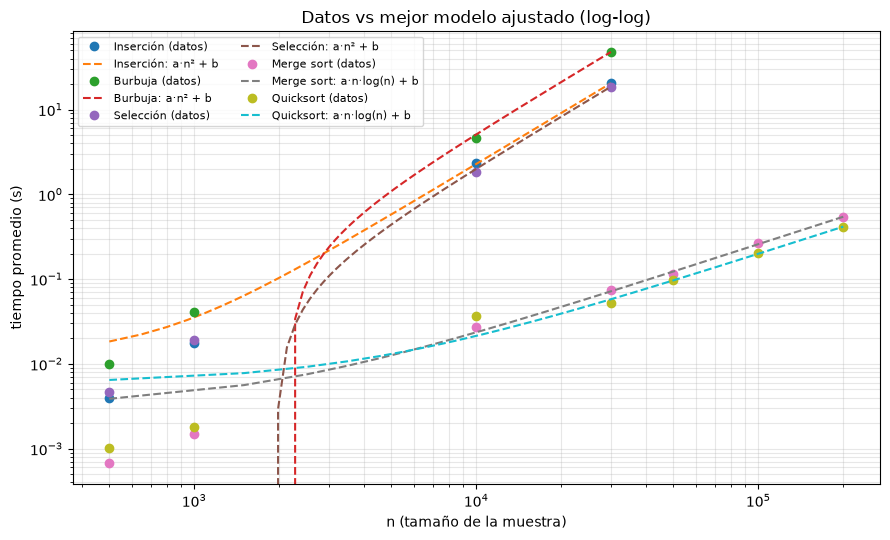

Pendiente log-log por algoritmo (referencia: ~1-1,2 para n·log n, ~2 para n²):
  Inserción  : 2.096
  Burbuja    : 2.066
  Selección  : 2.013
  Merge sort : 1.120
  Quicksort  : 1.000


In [22]:
# ---------------------- Curvas ajustadas superpuestas ----------------------
fig, ax = plt.subplots(figsize=(9, 5.5))
for nombre in ALGORITMOS:
    n_vals, t_vals = datos_ajuste[nombre]
    ax.plot(n_vals, t_vals, "o", label=f"{NOMBRES[nombre]} (datos)")
    if nombre in mejores:
        etiqueta = mejores[nombre]["modelo"]
        fn = MODELOS[etiqueta]
        nn = np.linspace(n_vals.min(), n_vals.max(), 200)
        ax.plot(nn, fn(nn, mejores[nombre]["a"], mejores[nombre]["b"]), "--",
                label=f"{NOMBRES[nombre]}: {etiqueta}")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Datos vs mejor modelo ajustado (log-log)")
ax.set_xlabel("n (tamaño de la muestra)")
ax.set_ylabel("tiempo promedio (s)")
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "ajustes.png", dpi=150)
plt.show()

print("Pendiente log-log por algoritmo (referencia: ~1-1,2 para n·log n, ~2 para n²):")
for nombre in ALGORITMOS:
    print(f"  {NOMBRES[nombre]:11s}: {mejores[nombre]['pendiente_loglog']:.3f}" if nombre in mejores else nombre)

## 10. Conclusiones

Resultados del **modo completo** (`QUICK_MODE = False`, 5 repeticiones, semilla 42).
Los O(n²) se corrieron hasta **n = 30.000**: por encima, la estimación superaba el
límite de tiempo y la corrida se omitió (sección 5). Merge sort y quicksort corrieron
los 7 tamaños, hasta 200.000.

### 10.1 Complejidad empírica vs. teórica

| algoritmo | mejor modelo | R² | RMSE | pendiente log-log |
|---|---|---|---|---|
| Inserción | `a·n² + b` | 0.999994 | 0.0216 | 2.10 |
| Burbuja | `a·n² + b` | 0.999757 | 0.3139 | 2.07 |
| Selección | `a·n² + b` | 0.999825 | 0.1035 | 2.01 |
| Merge sort | `a·n·log(n) + b` | 0.999058 | 0.0056 | 1.12 |
| Quicksort | `a·n·log(n) + b` | 0.997423 | 0.0070 | 1.00 |

El ajuste de curvas y la pendiente en escala log-log **confirman la teoría**: ≈2 para los
algoritmos cuadráticos y ≈1–1,2 para los de n·log n. La escala log-log es la que separa
con claridad las dos familias; en escala lineal los O(n²) crecen tanto que aplastan a
merge y quicksort contra el eje.

### 10.2 Constantes ocultas: los tiempos reales

Tiempo promedio en los puntos comparables:

| n | Inserción | Burbuja | Selección | Merge sort | Quicksort |
|---|---|---|---|---|---|
| 500 | 0.0039 s | 0.0099 s | 0.0047 s | 0.0007 s | 0.0010 s |
| 1.000 | 0.0176 s | 0.0409 s | 0.0191 s | 0.0015 s | 0.0018 s |
| 10.000 | 2.3203 s | 4.5645 s | 1.8242 s | 0.0276 s | 0.0370 s |
| 30.000 | 20.4506 s | 47.8461 s | 18.6374 s | 0.0745 s | 0.0519 s |
| 200.000 | — | — | — | 0.5404 s | 0.4149 s |

A n = 30.000, **quicksort es ≈390 veces más rápido que burbuja** (0.052 s vs 47.85 s) y
**merge sort ≈270 veces más rápido que inserción**. La misma asíntota no basta: los
coeficientes `a` (las *constantes ocultas*) son los que marcan la diferencia práctica.

### 10.3 Por qué burbuja es el peor de los cuadráticos

Burbuja hace **un intercambio por cada inversión**, y en Python cada intercambio es un
`tuple swap` con dos indexaciones; inserción mueve elementos con asignaciones simples y
selección solo **compara** y hace a lo sumo n−1 intercambios. Por eso, midiendo, burbuja
sale ≈2,5 veces más lenta que inserción y selección. Entre inserción y selección los
tiempos quedan prácticamente empatados (20.45 s vs 18.64 s a n = 30.000): selección hace
más comparaciones pero su bucle interno es más barato, así que en Python puro llega a
empatar con inserción en vez de ser claramente peor.

### 10.4 Escalabilidad: por qué los O(n²) no llegaron a 200.000

Extrapolando por n² desde n = 2.000, **una sola corrida** de los cuadráticos con 200.000
elementos tardaría: inserción ≈ 821 s, selección ≈ 796 s y burbuja ≈ 1888 s. Con 5
repeticiones son entre **66 y 157 minutos por algoritmo**, solo para ese tamaño. Merge
sort y quicksort, en cambio, ordenan los 200.000 elementos en **medio segundo**. Esa
diferencia es, en sí misma, el resultado más importante del taller: un algoritmo O(n²)
deja de ser viable cuando n crece, aunque para n pequeño sea competitivo.

### 10.5 ¿Qué información sobre los algoritmos da la gráfica?

1. **La forma (complejidad).** En escala lineal, los tres cuadráticos se disparan y los
   O(n log n) parecen una línea pegada al eje. En escala **log-log** las rectas tienen
   pendiente ≈2 (cuadráticos) y ≈1 (n·log n): la gráfica revela la familia de cada
   algoritmo.
2. **Las constantes (eficiencia relativa).** Dos algoritmos con la misma complejidad
   pueden ordenarse por su altura en la gráfica: burbuja queda por encima de inserción y
   selección.
3. **La escalabilidad (el cruce).** Muestra a partir de qué tamaño un algoritmo “bueno
   para pocos datos” se vuelve inútil, y por qué merge sort y quicksort mantienen un
   crecimiento manejable.
4. **La variabilidad.** La desviación estándar (barras/tabla) crece en los cuadráticos,
   señal de que el hardware y el intérprete pesan más cuando el tiempo es grande.

### 10.6 ¿Cuándo conviene cada algoritmo?

- **Inserción:** listas pequeñas o casi ordenadas (su mejor caso es O(n)).
- **Selección:** cuando el costo de **escribir/intercambiar** es alto (hace pocos
  intercambios), aunque no es estable.
- **Burbuja:** prácticamente solo con fines didácticos.
- **Merge sort:** cuando se necesita **estabilidad** y rendimiento predecible O(n log n),
  a cambio de memoria auxiliar.
- **Quicksort:** el más rápido en promedio con datos aleatorios y ordena in-place; usa
  pivote aleatorio para evitar el peor caso O(n²).